# Exploration de Caltech-101

Objectif : comprendre les catégories, les dimensions et quelques exemples avant de construire le système de recherche.

Dans le terminal, installe les dépendances du notebook si nécessaire : `python -m pip install notebook pillow`. Ouvre ce notebook depuis le dossier du projet et sélectionne le même environnement Python.

In [2]:
%pip install pillow
import sys
print(sys.executable)

  Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl (7.3 MB)
Note: you may need to restart the kernel to use updated packages.
c:\Users\zkira\Desktop\5IIR\Vendredi Aprem Vision Artificielle\Project_image_similarity_search\.venv\Scripts\python.exe


In [3]:
from pathlib import Path
from collections import Counter
from PIL import Image, ImageOps
from IPython.display import display

base = Path("data/101_ObjectCategories")
if not base.is_dir():
    raise FileNotFoundError(f"Dossier introuvable : {base.resolve()}. Ouvre le notebook depuis le dossier du projet.")

categories = sorted(p for p in base.iterdir() if p.is_dir())
images = sorted(base.glob("*/*.jpg"))
assert categories and images, "Aucune catégorie ou image JPEG trouvée."
print(f"Dossiers : {len(categories)}")
print(f"Images JPEG : {len(images)}")

Dossiers : 102
Images JPEG : 9144


## Nombre d’images par catégorie

Le dossier `BACKGROUND_Google` est conservé dans cette exploration ; son exclusion pour la recherche reste à décider.

In [4]:
comptes = Counter(p.parent.name for p in images)
for nom, nombre in sorted(comptes.items()):
    print(f"{nom:25} {nombre:4}")
print(f"\nPlus petite catégorie : {min(comptes.values())} images")
print(f"Plus grande catégorie : {max(comptes.values())} images")
print(f"Sans BACKGROUND_Google : {len(images) - comptes.get('BACKGROUND_Google', 0)} images")

BACKGROUND_Google          467
Faces                      435
Faces_easy                 435
Leopards                   200
Motorbikes                 798
accordion                   55
airplanes                  800
anchor                      42
ant                         42
barrel                      47
bass                        54
beaver                      46
binocular                   33
bonsai                     128
brain                       98
brontosaurus                43
buddha                      85
butterfly                   91
camera                      50
cannon                      43
car_side                   123
ceiling_fan                 47
cellphone                   59
chair                       62
chandelier                 107
cougar_body                 47
cougar_face                 69
crab                        73
crayfish                    70
crocodile                   50
crocodile_head              51
cup                         57
dalmatia

## Dimensions et fichiers illisibles

On ouvre chaque image pour relever ses dimensions et vérifier son décodage. Cette étape peut prendre quelques minutes.

In [5]:
dimensions = Counter()
illisibles = []
for chemin in images:
    try:
        with Image.open(chemin) as image:
            image.load()
            dimensions[image.size] += 1
    except (OSError, ValueError) as erreur:
        illisibles.append((chemin, str(erreur)))

assert sum(dimensions.values()) + len(illisibles) == len(images)
print(f"Images lisibles : {sum(dimensions.values())}")
print(f"Images illisibles : {len(illisibles)}")
print(f"Dimensions distinctes : {len(dimensions)}")
print("Dimensions les plus fréquentes (largeur, hauteur) :")
for taille, nombre in dimensions.most_common(10):
    print(f"  {taille} : {nombre}")
for chemin, erreur in illisibles:
    print(f"Illisible : {chemin} — {erreur}")

Images lisibles : 9144
Images illisibles : 0
Dimensions distinctes : 2255
Dimensions les plus fréquentes (largeur, hauteur) :
  (300, 225) : 315
  (300, 300) : 213
  (192, 128) : 168
  (300, 197) : 165
  (225, 300) : 110
  (300, 200) : 84
  (300, 199) : 50
  (300, 240) : 46
  (200, 300) : 45
  (300, 223) : 42


## Quelques exemples

Une image de chaque catégorie sélectionnée est affichée avec son nom. Les images originales ne sont pas modifiées.

airplanes — image_0001.jpg — taille originale : (398, 164)


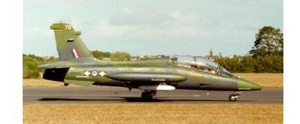

Motorbikes — image_0001.jpg — taille originale : (262, 161)


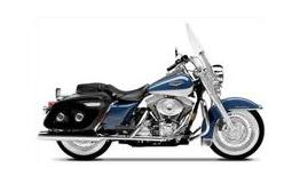

Faces — image_0001.jpg — taille originale : (510, 337)


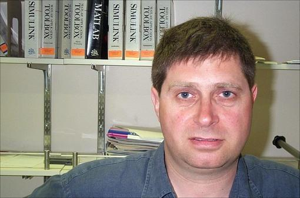

watch — image_0001.jpg — taille originale : (300, 242)


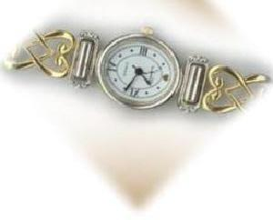

BACKGROUND_Google — image_0001.jpg — taille originale : (145, 144)


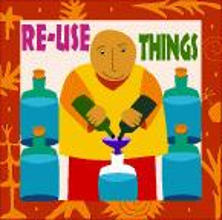

In [6]:
for nom in ["airplanes", "Motorbikes", "Faces", "watch", "BACKGROUND_Google"]:
    exemples = sorted((base / nom).glob("*.jpg"))
    if not exemples:
        print(f"Aucune image trouvée pour {nom}")
        continue
    try:
        with Image.open(exemples[0]) as image:
            apercu = ImageOps.contain(image.convert("RGB"), (300, 220))
            print(f"{nom} — {exemples[0].name} — taille originale : {image.size}")
            display(apercu)
    except (OSError, ValueError) as erreur:
        print(f"Impossible d’ouvrir {exemples[0]} : {erreur}")

## À retenir

- Les catégories sont de tailles différentes : il faudra en tenir compte dans l’évaluation.
- Les tailles d’images peuvent varier : le prétraitement devra les harmoniser.
- La catégorie de fond n’est pas une catégorie d’objet ; son traitement sera documenté avant l’évaluation.